# Process tomography for DB-QITE using DME
## 1. Define the DME circuit

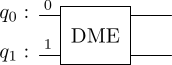

In [1]:
import sys; sys.path.append('..')
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import Gate, Parameter
from qiskit.circuit.library import RZZGate
from qiskit_aer import AerSimulator
from qiskit_experiments.library.tomography import ProcessTomography
from functions.plot_process_matrix import plot_process_matrix

# Define symbolic parameter
t = np.pi*0.14

# Create subcircuit with symbolic parameter
subcircuit = QuantumCircuit(2, name='DME')

# ZZ gate
subcircuit.append(RZZGate(t), [0, 1])

# YY gate
subcircuit.sdg(0)
subcircuit.sdg(1)
subcircuit.h(0)
subcircuit.h(1)
subcircuit.append(RZZGate(t), [0, 1])
subcircuit.h(0)
subcircuit.h(1)
subcircuit.s(0)
subcircuit.s(1)

# XX gate
subcircuit.h(0)
subcircuit.h(1)
subcircuit.append(RZZGate(t), [0, 1])
subcircuit.h(0)
subcircuit.h(1)

# Convert subcircuit to a parameterized gate
dme_gate = subcircuit.to_gate(label="DME")

# Use the gate in another circuit
qc = QuantumCircuit(2)
qc.append(dme_gate, [0, 1])

# Assign value to the parameter
qc.draw(output='latex', style="bw")


## 2. Circuit A: k1, M1

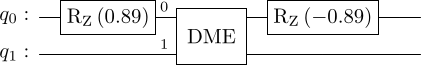

In [2]:
# 1. Create a quantum circuit with two qubits
qc = QuantumCircuit(2)
phi_z = 0.89
qc.rz(phi=phi_z,qubit=0)
qc.append(dme_gate, [0, 1])  # DME gate on q_0 and q_1
qc.rz(phi=-phi_z,qubit=0)
# Draw the circuit
qc.draw(output='latex', style="bw")

In [3]:
# 2. Set up the process tomography experiment
process_tomo = ProcessTomography(qc)

# 3. Run the experiment
simulator = AerSimulator()
tomo_job = process_tomo.run(simulator)
tomo_result = tomo_job.block_for_results()

# 4. Analyze the results
from qiskit.quantum_info import Choi

# List all available analysis results
for res in tomo_result.analysis_results():
    print(res.name, res.value)

# Typically, you can extract the Choi matrix like this:
choi = tomo_result.analysis_results()[0].value
print(Choi(choi))


state Choi([[ 9.52702525e-01+0.00000000e+00j,  1.25306309e-02-1.98076251e-03j,
        5.39208751e-03+1.17878305e-02j,  2.24048285e-03+1.35268492e-02j,
        3.93922923e-03-7.98012361e-03j,  7.98053595e-01-3.70814380e-01j,
        4.00546257e-01+9.95548386e-02j,  2.52502046e-02-6.15593164e-03j,
        1.66631950e-03+1.50119139e-02j, -1.68884500e-01+3.52371209e-01j,
        8.00217512e-01-3.99930274e-01j,  3.65010062e-03-8.75629044e-03j,
        3.17957436e-03-8.44166618e-03j, -1.32641371e-02+3.29837624e-03j,
       -1.25629287e-02-4.37112484e-03j,  9.25946381e-01-1.11396426e-02j],
      [ 1.25306309e-02+1.98076251e-03j,  8.02281421e-03+2.16840434e-19j,
        8.31037584e-04-2.14254057e-03j, -1.41574578e-03-5.12036077e-03j,
       -2.25071448e-03+1.96824901e-03j,  2.57612181e-03-6.07662442e-03j,
        4.07936892e-03+4.81578949e-04j,  1.79392526e-04+5.97233800e-03j,
        9.10343026e-04-5.86169356e-03j, -2.99591679e-03+3.65837171e-03j,
        1.00664568e-02-3.06693507e-03j, -3.0

C:\Users\Admin\AppData\Local\Temp\ipykernel_2160\3750241050.py:13: DeprecationWarning: Leaving `dataframe` unset or setting it to `False` for `ExperimentData.analysis_results` is deprecated as of qiskit-experiments 0.9.0. Future releases may change the default to `True` and remove the option to set the value to `False`.
  for res in tomo_result.analysis_results():
C:\Users\Admin\AppData\Local\Temp\ipykernel_2160\3750241050.py:17: DeprecationWarning: Leaving `dataframe` unset or setting it to `False` for `ExperimentData.analysis_results` is deprecated as of qiskit-experiments 0.9.0. Future releases may change the default to `True` and remove the option to set the value to `False`.
  choi = tomo_result.analysis_results()[0].value


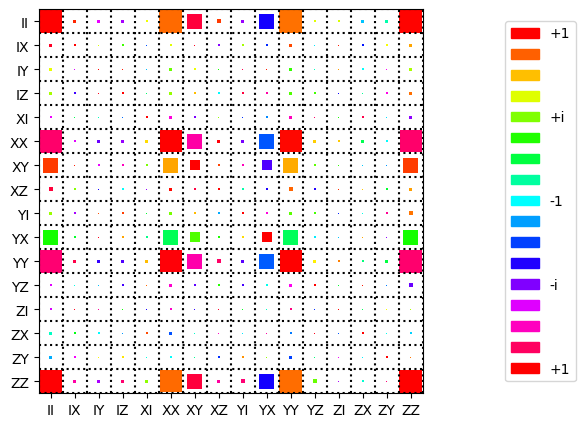

In [4]:
# Assuming 1-qubit process
pauli_labels = ["I", "X", "Y", "Z"]
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
 'XI', 'XX', 'XY', 'XZ',
 'YI', 'YX', 'YY', 'YZ',
 'ZI', 'ZX', 'ZY', 'ZZ']
plot_process_matrix(np.asarray(choi), pauli_labels_2q)